# Programa A — Revisión y Corrección del Etiquetado
**Evaluación Sumativa 2 — Machine Learning**

**Integrantes:** 
- Víctor Rubilar
- Alexis Salazar
- Maximiliano Gonzalez

## 1. Importar Librerías y Configurar Rutas

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Rutas del proyecto
BASE_DIR = Path(".")
CARPETA_IMAGENES = BASE_DIR / "imagenes"
ARCHIVO_ETIQUETAS = CARPETA_IMAGENES / "etiquetas.csv"

ETIQUETAS_VALIDAS = ["circulo", "triangulo", "cuadrado"]

print("Carpeta de imágenes:", CARPETA_IMAGENES.resolve())
print("Archivo de etiquetas:", ARCHIVO_ETIQUETAS.resolve())

.
Carpeta de imágenes: /home/alerrsi/Documents/ML/eva2/evaluacion-2-machine-learning/imagenes
Archivo de etiquetas: /home/alerrsi/Documents/ML/eva2/evaluacion-2-machine-learning/imagenes/etiquetas.csv


## 2. Cargar Dataset de Etiquetas

In [2]:
df_etiquetas = pd.read_csv(ARCHIVO_ETIQUETAS)

print(f"Total de registros cargados: {len(df_etiquetas)}")
display(df_etiquetas.head(10))

Total de registros cargados: 91


,archivo,etiqueta
0,img_001.png,circulo
1,img_002.png,circulo
2,img_003.png,circulo
3,img_004.png,circulo
4,img_005.png,cuadrado
5,img_006.png,circulo
6,img_007.png,circulo
7,img_008.png,circulo
8,img_009.png,circulo
9,img_010.png,circulo


## 3. Visualizador de Imágenes por Lotes
Ejecuta esta celda para revisar bloques de imágenes y sus etiquetas correspondientes.

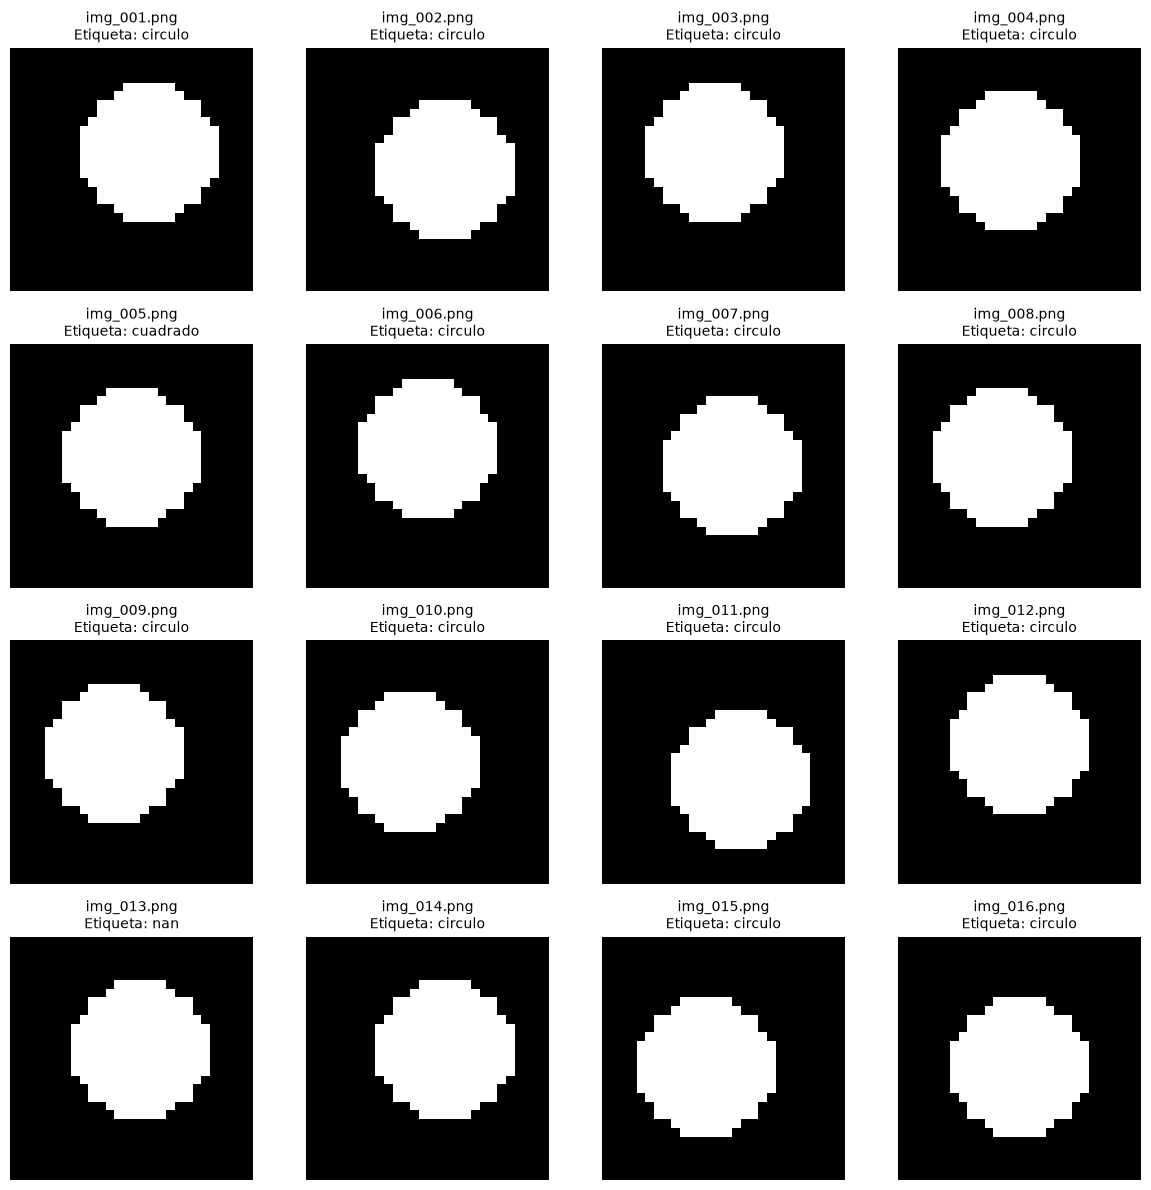

In [3]:
def mostrar_lote(df, inicio=0, cantidad=16):
    """Muestra una cuadrícula de imágenes con sus etiquetas."""
    sub_df = df.iloc[inicio:inicio+cantidad]
    columnas = 4
    filas = (len(sub_df) + columnas - 1) // columnas
    
    plt.figure(figsize=(12, 3 * filas))
    
    for idx, (_, fila) in enumerate(sub_df.iterrows(), start=1):
        ruta_img = CARPETA_IMAGENES / fila["archivo"]
        plt.subplot(filas, columnas, idx)
        
        if ruta_img.exists():
            img = Image.open(ruta_img)
            plt.imshow(img, cmap="gray")
            plt.title(f"{fila['archivo']}\nEtiqueta: {fila['etiqueta']}", fontsize=10)
        else:
            plt.title(f"{fila['archivo']}\n[NO EXISTE]", color="red", fontsize=10)
            
        plt.axis("off")
        
    plt.tight_layout()
    plt.show()

mostrar_lote(df_etiquetas, inicio=0, cantidad=16)

## 4. Función para Corregir Etiquetas Individuales

In [10]:
def corregir_etiqueta(nombre_archivo, nueva_etiqueta):
    """Actualiza la etiqueta de una imagen específica."""
    nueva_etiqueta = str(nueva_etiqueta).strip().lower()
    if nueva_etiqueta not in ETIQUETAS_VALIDAS:
        print(f"    Error: '{nueva_etiqueta}' no es válida. Debe ser una de: {ETIQUETAS_VALIDAS}")
        return
        
    mask = df_etiquetas["archivo"] == nombre_archivo
    if not mask.any():
        print(f"Archivo '{nombre_archivo}' no encontrado en el dataset.")
        return
        
    df_etiquetas.loc[mask, "etiqueta"] = nueva_etiqueta
    print(f"✓ Actualizado '{nombre_archivo}' -> '{nueva_etiqueta}'")


## 5. Corrección por Lista o Lote (Opcional)
Si ya identificaste varios errores visualmente, puedes aplicarlos todos juntos aquí:

In [14]:
correcciones = {}

for archivo, nueva_etq in correcciones.items():
    corregir_etiqueta(archivo, nueva_etq)

## 6. Guardar Cambios en `etiquetas.csv`

In [15]:
# Guardar el archivo modificado de vuelta en la carpeta imagenes/
df_etiquetas.to_csv(ARCHIVO_ETIQUETAS, index=False)
print(f"✓ Archivo guardado con éxito en: {ARCHIVO_ETIQUETAS.resolve()}")

✓ Archivo guardado con éxito en: /home/alerrsi/Documents/ML/eva2/evaluacion-2-machine-learning/imagenes/etiquetas.csv
